In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("fakenews.csv")

# Handle missing values
df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)

# Combine headline and body text
df["text"] = df["headline"] + " " + df["body_text"]

print("Dataset loaded successfully!")
print("Total articles:", len(df))

print("\nNews categories:")
print(df["label"].value_counts())

print("\nSample data:")
print(df[["label", "text"]].head())

Dataset loaded successfully!
Total articles: 2212

News categories:
label
Fake    1110
Real    1102
Name: count, dtype: int64

Sample data:
  label                                               text
0  Real  Global economy faces recession The Prime Minis...
1  Real  Earthquake hits Chittagong, panic spreads Gove...
2  Fake  Breakthrough in Bangladesh's tech industry Loc...
3  Fake  Dengue situation worsens in the country The Pr...
4  Real  New virus outbreak sparks fear Government sour...


In [2]:
# Function to calculate stylistic features
def analyze_style(text):
    text = str(text)

    # Count total characters and letters
    letters = [char for char in text if char.isalpha()]

    # Count uppercase letters
    uppercase_letters = sum(char.isupper() for char in letters)

    # Count words written entirely in uppercase
    words = re.findall(r"\b[A-Za-z]+\b", text)
    uppercase_words = sum(word.isupper() for word in words if len(word) > 1)

    # Count punctuation marks
    exclamation_count = text.count("!")
    question_count = text.count("?")
    ellipsis_count = text.count("...")

    # Count repeated punctuation patterns
    repeated_punctuation = len(re.findall(r"[!?]{2,}", text))

    # Calculate percentages safely
    uppercase_percentage = (
        uppercase_letters / len(letters) * 100 if letters else 0
    )

    uppercase_word_percentage = (
        uppercase_words / len(words) * 100 if words else 0
    )

    return pd.Series({
        "exclamation_count": exclamation_count,
        "question_count": question_count,
        "ellipsis_count": ellipsis_count,
        "repeated_punctuation": repeated_punctuation,
        "uppercase_percentage": round(uppercase_percentage, 2),
        "uppercase_word_percentage": round(uppercase_word_percentage, 2)
    })


print("Stylistic feature function created successfully!")

Stylistic feature function created successfully!


In [3]:
# Analyze stylistic features in each article
style_features = df["text"].apply(analyze_style)

# Combine features with news labels
style_df = pd.concat(
    [df[["news_id", "label"]].reset_index(drop=True),
     style_features.reset_index(drop=True)],
    axis=1
)

# Display results
print(style_df.head(10))

   news_id label  exclamation_count  question_count  ellipsis_count  \
0        1  Real                0.0             0.0             0.0   
1        2  Real                0.0             0.0             0.0   
2        3  Fake                0.0             0.0             0.0   
3        4  Fake                0.0             0.0             0.0   
4        5  Real                0.0             0.0             0.0   
5        6  Fake                0.0             0.0             0.0   
6        7  Fake                0.0             0.0             0.0   
7        8  Real                0.0             0.0             0.0   
8        9  Fake                0.0             0.0             0.0   
9       10  Real                0.0             0.0             0.0   

   repeated_punctuation  uppercase_percentage  uppercase_word_percentage  
0                   0.0                  4.49                        0.0  
1                   0.0                  3.06                       

In [4]:
# Compare average stylistic features by news category
style_comparison = (
    style_df.groupby("label")
    .mean(numeric_only=True)
    .round(2)
)

# Display comparison
print("Stylistic Feature Comparison: Real vs Fake News\n")
print(style_comparison)

Stylistic Feature Comparison: Real vs Fake News

       news_id  exclamation_count  question_count  ellipsis_count  \
label                                                               
Fake   1102.36                0.0             0.0             0.0   
Real   1110.67                0.0             0.0             0.0   

       repeated_punctuation  uppercase_percentage  uppercase_word_percentage  
label                                                                         
Fake                    0.0                  3.27                        0.0  
Real                    0.0                  3.37                        0.0  


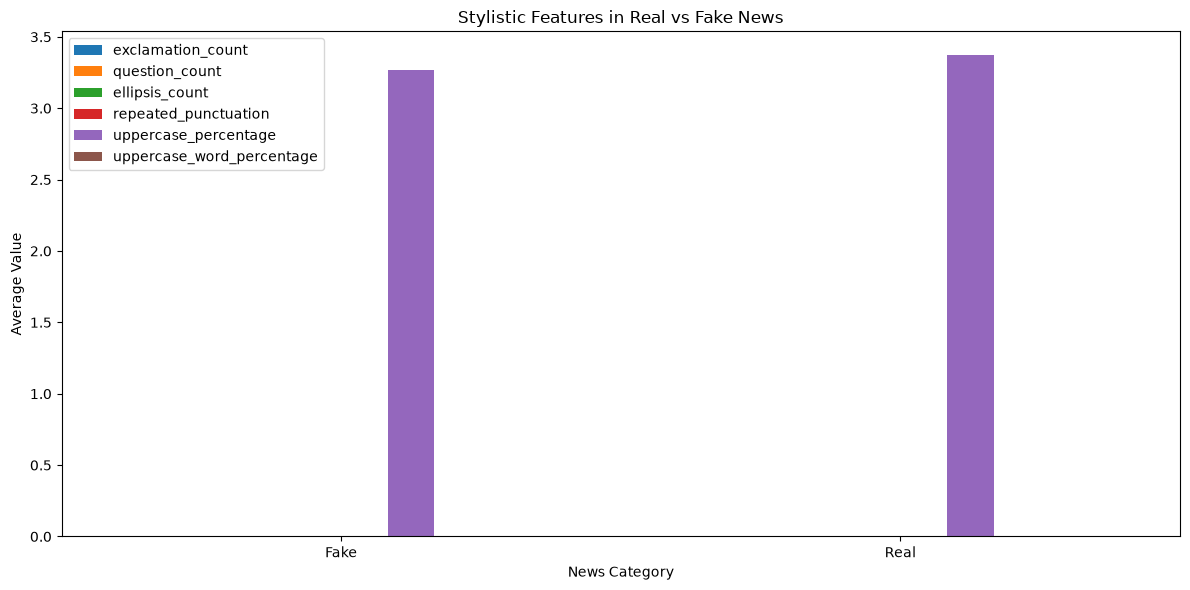

In [5]:
# Select stylistic features for visualization
plot_columns = [
    "exclamation_count",
    "question_count",
    "ellipsis_count",
    "repeated_punctuation",
    "uppercase_percentage",
    "uppercase_word_percentage"
]

# Plot comparison
style_comparison[plot_columns].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Stylistic Features in Real vs Fake News")
plt.xlabel("News Category")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
# Save article-level stylistic analysis
style_df.to_csv("T24_stylistic_analysis.csv", index=False)

# Save Real vs Fake comparison
style_comparison.to_csv("T24_stylistic_comparison.csv")

print("Results saved successfully!")
print("1. T24_stylistic_analysis.csv")
print("2. T24_stylistic_comparison.csv")

Results saved successfully!
1. T24_stylistic_analysis.csv
2. T24_stylistic_comparison.csv
